# 04. Généralisation à un sujet jamais vu (leave-one-subject-out)

**Question :** un modèle appris sur d'autres personnes fonctionne-t-il sur un nouvel utilisateur,
sans calibration étiquetée ? C'est l'enjeu pratique d'une BCI « prête à l'emploi ».

**Protocole**, pour chaque sujet testé : apprentissage sur les 2 sessions des 8 autres sujets
(4 608 essais), test sur la session 2 du sujet, c'est-à-dire exactement les essais de test de
l'évaluation inter-session des phases 2 et 3. On compare donc, sur les mêmes essais :
- **modèle propre au sujet** : appris sur sa propre session 1 (phase 3) ;
- **autres sujets, sans recentrage** ;
- **autres sujets, avec recentrage riemannien**, la référence du sujet testé étant calculée sans
  étiquette soit sur sa session 1 (*calibration* : aucun essai de test utilisé), soit sur les
  essais de test eux-mêmes (*transductif* : courant dans la littérature, mais optimiste).

Code : `src/alignement.py` (recentrage) et `src/phase4_inter_sujets.py`.

In [1]:
import os, sys
from pathlib import Path
RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(RACINE); sys.path.insert(0, str(RACINE))
import pandas as pd
from IPython.display import Image, display

## 1. Pourquoi les sujets ne se ressemblent pas, et ce que fait le recentrage

Sans recentrage, le premier axe de l'ACP (54 % de la variance) sépare surtout les **sujets**, pas les classes :
chaque personne occupe sa propre région de la variété (anatomie, impédance, placement du casque).
Le recentrage C -> M^(-1/2) C M^(-1/2) amène la moyenne de chaque sujet sur l'identité : il ne garde que
les écarts *relatifs* à l'état moyen du sujet, et ces écarts se ressemblent davantage d'une personne à l'autre.

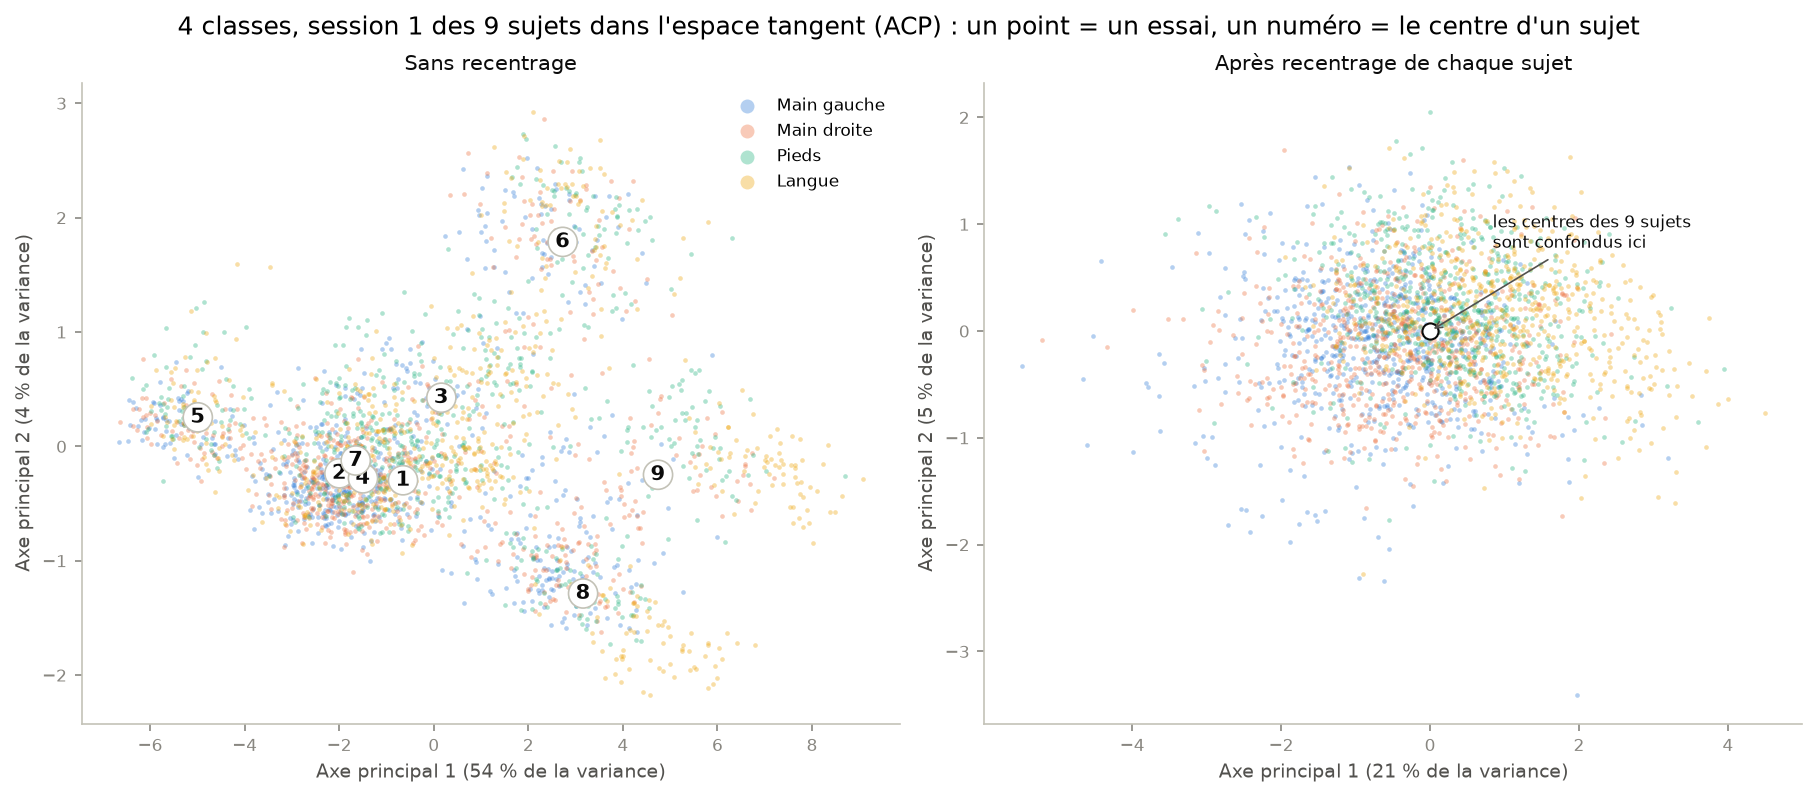

In [2]:
display(Image("reports/figures/phase4_espace_tangent.png"))

## 2. Perte et gain, en moyenne

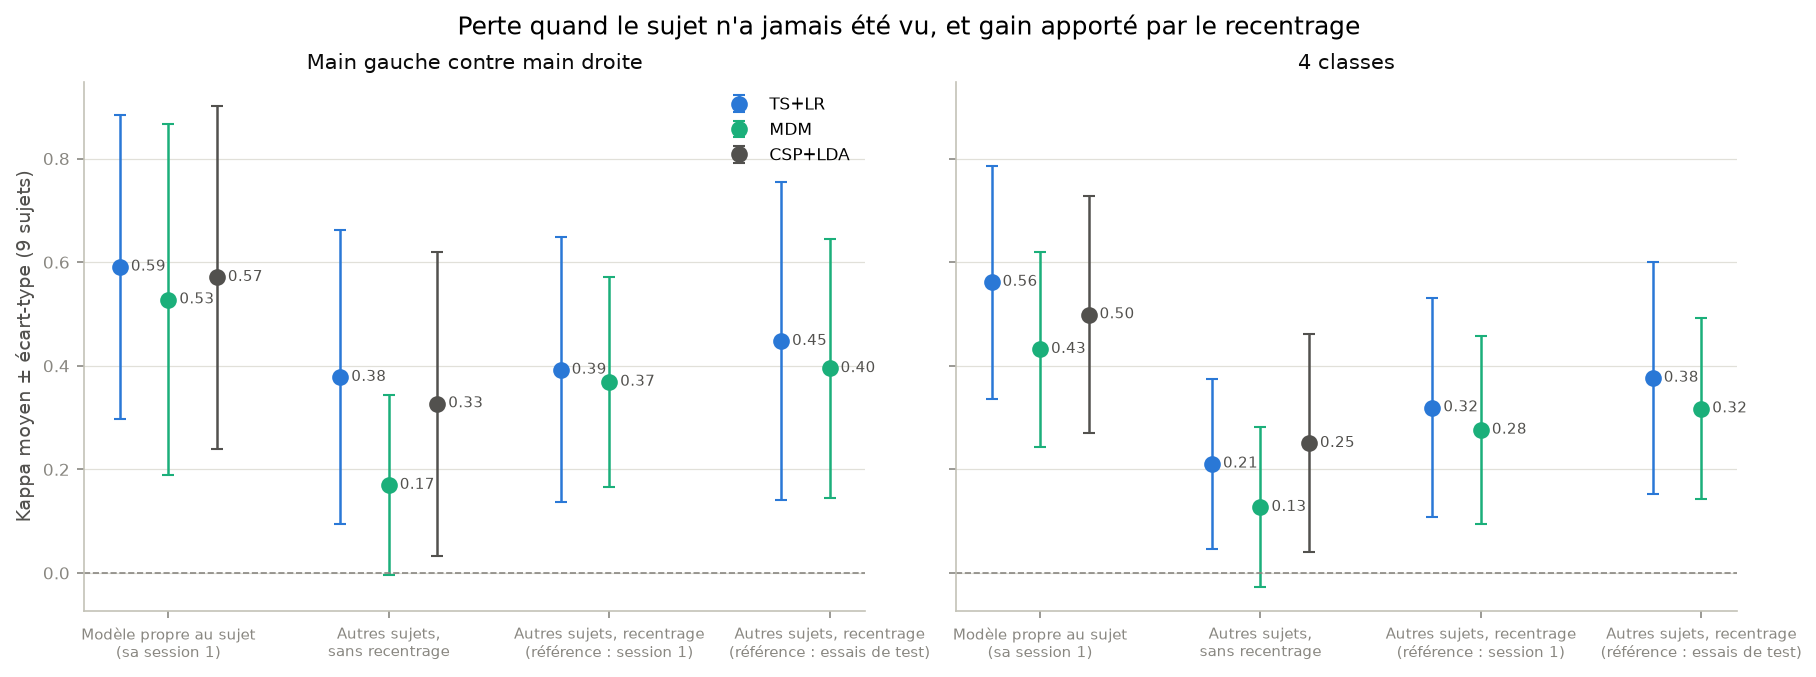

In [3]:
display(Image("reports/figures/phase4_resume_methodes.png"))

In [4]:
resume = pd.read_csv("results/phase4_resume.csv")
resume.pivot_table(index=["methode", "alignement"], columns="tache", values="kappa_moyen").round(3)

tache                    4classes  binaire
methode alignement                        
CSP+LDA aucun               0.250    0.327
        propre au sujet     0.499    0.571
MDM     aucun               0.127    0.170
        calibration         0.276    0.369
        propre au sujet     0.432    0.528
        transductif         0.317    0.395
TS+LR   aucun               0.211    0.378
        calibration         0.319    0.392
        propre au sujet     0.562    0.591
        transductif         0.376    0.448

In [5]:
pd.read_csv("results/phase4_recuperation.csv").round(3)

,tache,alignement,perte_kappa_sans_recentrage,gain_kappa_recentrage,part_de_la_perte_recuperee
0,binaire,calibration,0.213,0.014,0.065
1,binaire,transductif,0.213,0.069,0.326
2,4classes,calibration,0.351,0.108,0.309
3,4classes,transductif,0.351,0.166,0.472


## 3. Sujet par sujet (TS+LR)

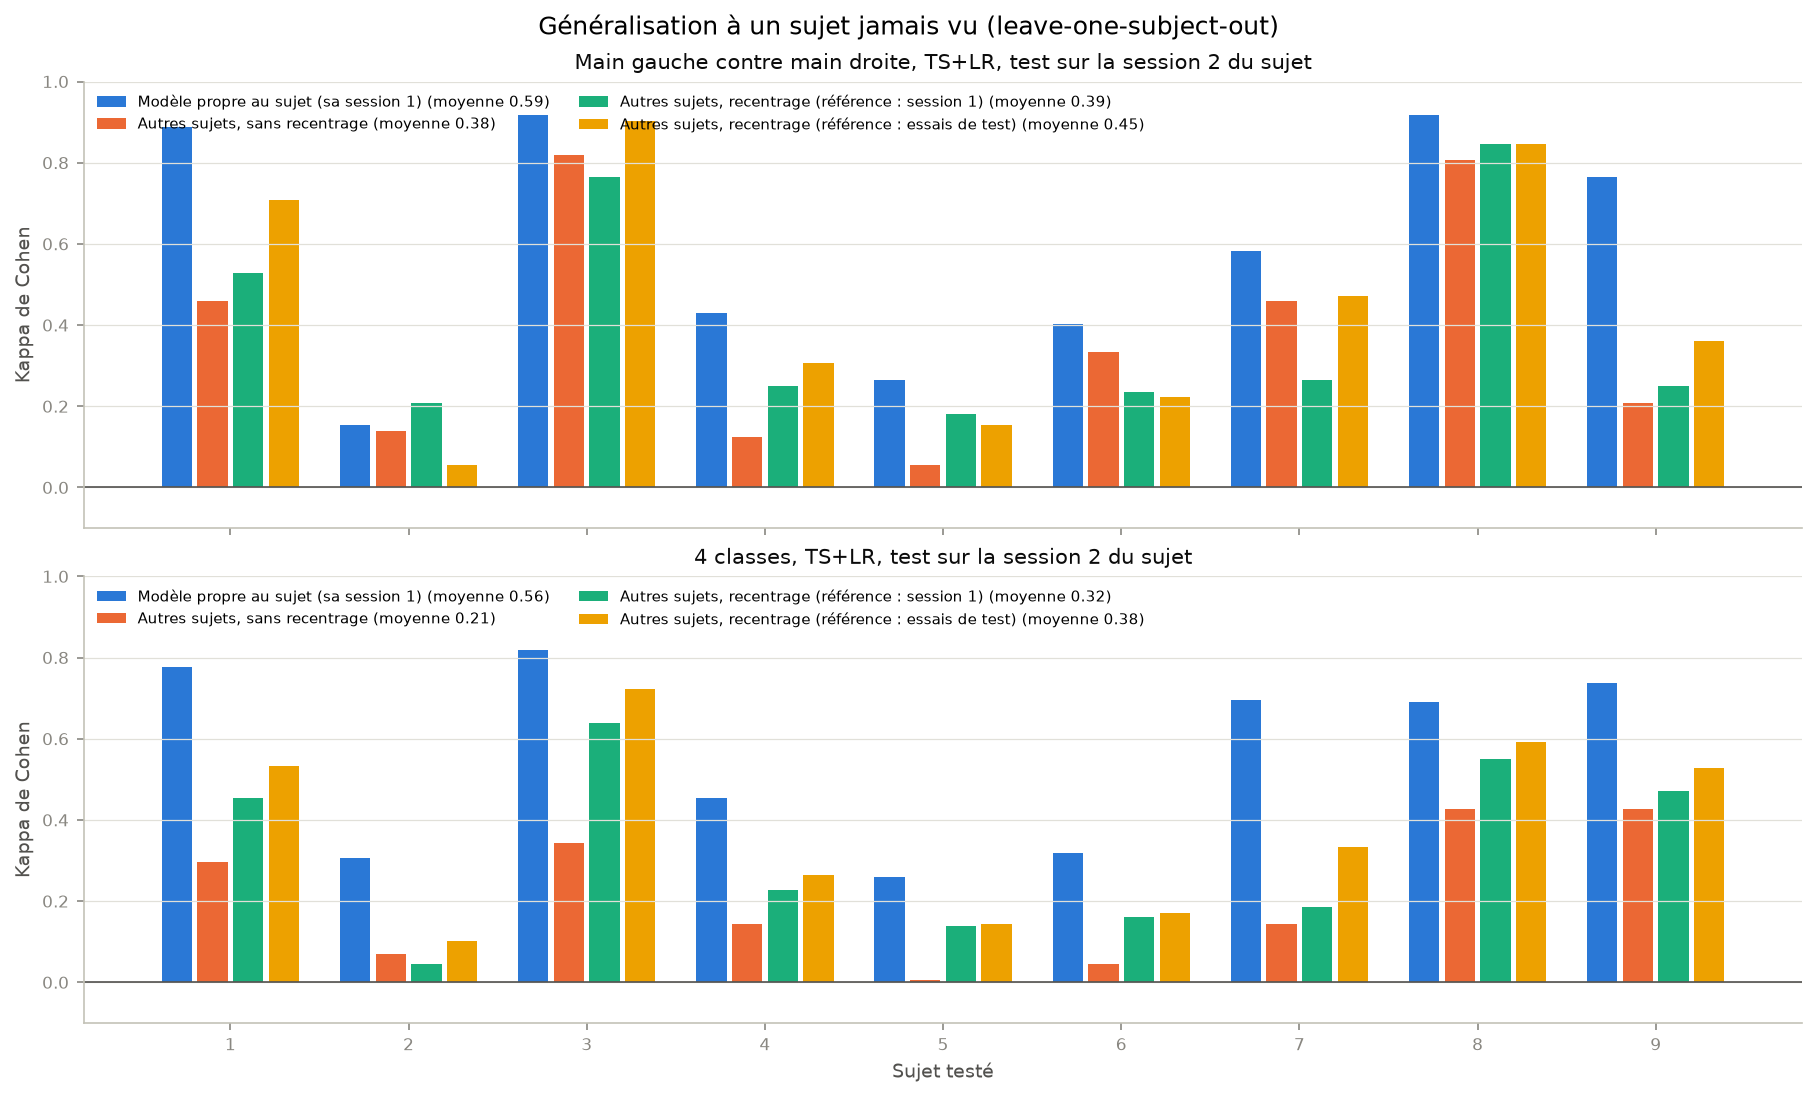

In [6]:
display(Image("reports/figures/phase4_kappa_par_sujet.png"))

## 4. Tests de Wilcoxon appariés (9 sujets, correction de Holm sur les 12 tests)

In [7]:
pd.read_csv("results/phase4_wilcoxon.csv")[["tache", "methode", "alignement_a", "alignement_b",
    "kappa_moyen_a", "kappa_moyen_b", "difference_moyenne", "sujets_a_meilleur", "p_valeur",
    "p_valeur_holm"]].round(3)

,tache,methode,alignement_a,alignement_b,kappa_moyen_a,kappa_moyen_b,difference_moyenne,sujets_a_meilleur,p_valeur,p_valeur_holm
0,binaire,TS+LR,aucun,propre au sujet,0.378,0.591,-0.213,0,0.004,0.047
1,binaire,TS+LR,calibration,aucun,0.392,0.378,0.014,6,0.648,0.648
2,binaire,TS+LR,transductif,aucun,0.448,0.378,0.069,7,0.129,0.258
3,binaire,TS+LR,calibration,propre au sujet,0.392,0.591,-0.199,1,0.008,0.062
4,binaire,MDM,calibration,aucun,0.369,0.170,0.199,8,0.027,0.109
5,binaire,MDM,transductif,aucun,0.395,0.170,0.225,8,0.008,0.062
6,4classes,TS+LR,aucun,propre au sujet,0.211,0.562,-0.351,0,0.004,0.047
7,4classes,TS+LR,calibration,aucun,0.319,0.211,0.108,8,0.008,0.062
8,4classes,TS+LR,transductif,aucun,0.376,0.211,0.166,9,0.004,0.047
9,4classes,TS+LR,calibration,propre au sujet,0.319,0.562,-0.242,0,0.004,0.047
